In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture

# 밀도 기반(Density-Based Spatial Cluctering of Applications with Noise, DBSCAN)

밀도 기반 클러스터링은 데이터 공간을 다루는 알고리즘으로 `전체 공간에서 데이터가 가장 밀집된 영역`을 찾는다. 그 `밀집된 영역이 하나의 클러스터`가 되며, 밀집 정도가 낮은 영역을 클러스터 외부 영역으로 구분한다. 이때, 밀집 정도를 파악하기 위해서 데이터 포인트간 거리를 측정하게 되는데, 거리를 어떤 방법으로 측정하느냐에 따라 클러스터 형태가 달라진다.

거리 측정 방법은 밀도 기반 클러스터링 객체를 생성할 때 조절 가능하며, 기본값은 유클리드 거리를 사용한다. `클러스터 개수를 사전에 정하지 않아도 된다.`

밀도 기반 클러스터링의 핵심 아이디어는 일정 반경 내에 최소한의 데이터 포인트 개수 이상이 존재한다는 것으로 반경의 최소한의 데이터 포인트 개수가 밀도 기반 클러스터링의 필수 요소이다.

## 사이킷런에서 제공하는 데이터를 이용하는 밀도 기반 클러스터링 알고리즘을 적용한다.

make_moons() 메소드는 사이킷런이 제공하는 초승달 모양의 클러스터 개수가 2개인 데이터를 랜덤하게 불러온다.  
`n_samples`의 기본값은 100이고 랜덤하게 만들 데이터 개수를 지정한다.  
`noise`로 데이터가 흩어지는 정도를 지정한다.

In [2]:
x_train, y_train = datasets.make_moons(n_samples=300, noise=0.05, random_state=23)
print(x_train.shape, y_train.shape)

for i in range(len(x_train))[:5]:
    print(x_train[i], y_train[i])

(300, 2) (300,)
[ 0.25787433 -0.2309611 ] 1
[-0.68625107  0.71065245] 0
[ 0.84743125 -0.41150714] 1
[ 0.19778116 -0.07190862] 1
[0.91497194 0.32573298] 0


## 클러스터링 적용 전 데이터 시각화

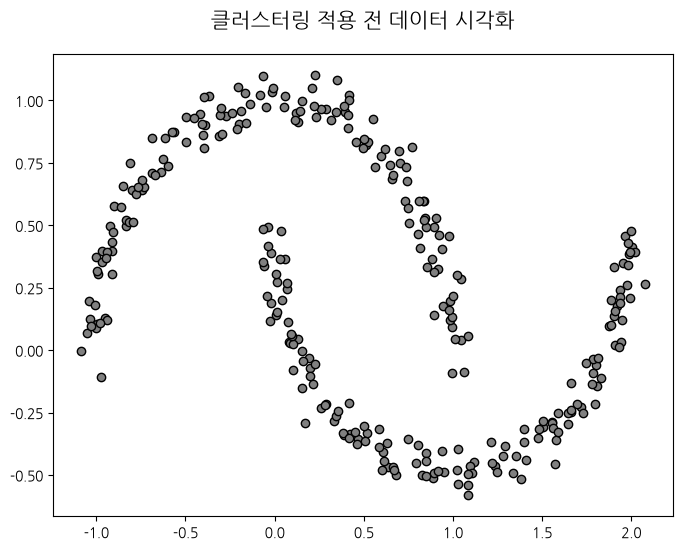

In [3]:
plt.figure(figsize=[8, 6])
plt.scatter(x_train[:, 0], x_train[:, 1], c='gray', edgecolors='black', marker='o')
plt.title('클러스터링 적용 전 데이터 시각화', pad=20, fontsize=15)
plt.show()

## k평균 클러스터링 모델 생성 후 학습 결과 시각화

In [4]:
model = KMeans(n_clusters=2)
model.fit(x_train)
print(model.labels_)

[0 0 1 0 1 0 0 0 0 0 1 0 0 1 1 1 0 1 0 1 0 0 0 1 1 1 0 0 1 0 0 1 1 1 1 0 1
 0 1 1 0 1 0 0 1 0 0 0 1 1 0 0 0 0 0 1 1 1 0 1 1 1 0 0 1 1 0 1 1 0 0 0 1 0
 1 1 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 0 1 1 0 0 0 0 1 0 1 0 0 1 0
 1 0 0 0 0 1 1 0 1 0 1 0 1 0 1 1 0 1 0 1 0 1 1 0 1 1 1 0 1 0 1 0 0 1 1 0 0
 1 0 1 0 1 1 1 1 1 0 0 1 0 1 0 0 1 0 1 0 0 1 1 1 1 1 1 0 0 0 1 1 1 0 1 1 1
 0 1 1 1 0 0 1 1 0 1 0 0 1 1 0 1 0 0 0 0 1 0 0 1 0 1 1 0 1 0 1 1 0 1 1 1 1
 0 1 1 0 1 1 0 0 0 1 1 0 1 0 0 1 1 1 1 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 1 0 1
 1 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 0 0 0 1 0 0 0 0 1 1 1 1 1 0 1 1 0 0 1 1
 1 0 1 0]


In [5]:
df = pd.DataFrame(x_train, columns=['x', 'y'])
df['label_1'] = y_train # make_moons() 메소드를 실행해서 얻은 클러스터의 중심
df['label_2'] = model.labels_ # k평균 클러스터링 알고리즘으로 얻은 클러스터의 중심
df.head(20)

,x,y,label_1,label_2
0,0.257874,-0.230961,1,0
1,-0.686251,0.710652,0,0
2,0.847431,-0.411507,1,1
3,0.197781,-0.071909,1,0
4,0.914972,0.325733,0,1
5,-0.952019,0.128681,0,0
6,0.514135,0.820107,0,0
7,0.118170,0.948977,0,0
8,-1.038048,0.125257,0,0
9,-0.914294,0.303833,0,0


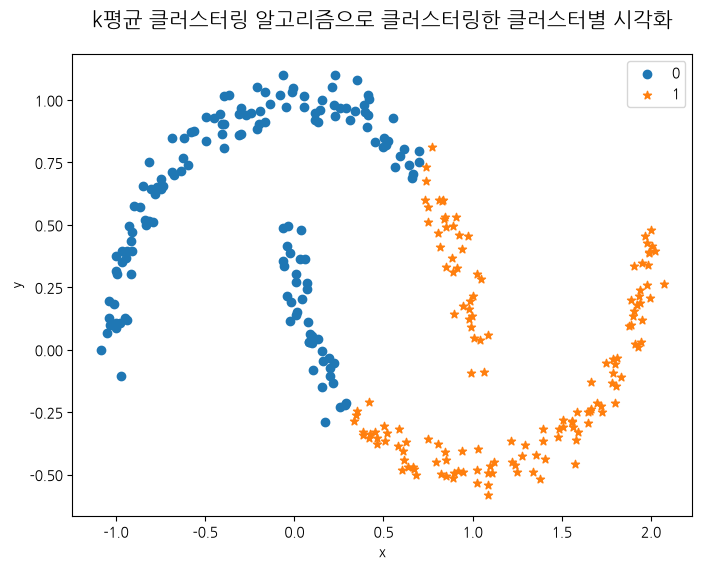

In [6]:
plt.figure(figsize=[8, 6])
markers = ['o', '*']

for index, marker in enumerate(markers):
    df_index = df[df.label_2 == index]
    plt.scatter(x=df_index.x, y=df_index.y, label=index, marker=marker)

plt.title('k평균 클러스터링 알고리즘으로 클러스터링한 클러스터별 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [7]:
score = silhouette_score(x_train, model.labels_)
print(score)

0.49014409518142504


## 병합 계층 클러스터링 모델 생성 후 학습 결과 시각화

In [8]:
model = AgglomerativeClustering(n_clusters=2, linkage='complete')
model.fit(x_train)
print(model.labels_)

[0 0 1 0 1 0 0 0 0 0 1 0 0 1 1 1 0 1 0 1 0 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1
 0 1 1 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 0 1 0 0 0 0 1 1 0 1 1 0 0 0 1 0
 1 1 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 0 1 1 0 0 0 0 1 0 1 0 0 1 0
 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1 0 1 0 0 0 1 1 0 1 1 0 0 1 0 1 0 0 1 1 0 0
 1 0 0 0 1 1 1 1 1 0 0 1 0 1 0 0 1 0 1 0 0 1 1 1 1 0 1 0 0 0 1 1 1 0 1 1 1
 0 1 1 1 0 0 1 1 0 1 0 0 1 1 0 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 1 0 1 1 1 1
 0 0 0 0 1 1 0 0 0 1 1 0 1 0 0 1 1 1 1 0 0 1 0 1 0 0 0 1 1 0 0 0 1 0 1 0 1
 0 1 1 1 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 1 0 0 0 0 0 1 1 1 0 0 1 1 0 0 0 1
 0 0 1 0]


In [9]:
df = pd.DataFrame(x_train, columns=['x', 'y'])
df['label_1'] = y_train # make_moons() 메소드를 실행해서 얻은 클러스터의 중심
df['label_2'] = model.labels_ # 병합 계층 클러스터링 알고리즘으로 얻은 클러스터의 중심
df.head(20)

,x,y,label_1,label_2
0,0.257874,-0.230961,1,0
1,-0.686251,0.710652,0,0
2,0.847431,-0.411507,1,1
3,0.197781,-0.071909,1,0
4,0.914972,0.325733,0,1
5,-0.952019,0.128681,0,0
6,0.514135,0.820107,0,0
7,0.118170,0.948977,0,0
8,-1.038048,0.125257,0,0
9,-0.914294,0.303833,0,0


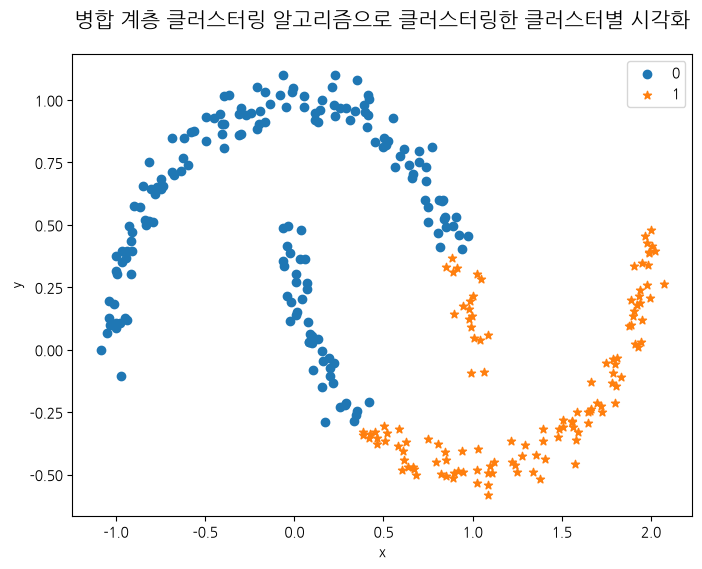

In [10]:
plt.figure(figsize=[8, 6])
markers = ['o', '*']

for index, marker in enumerate(markers):
    df_index = df[df.label_2 == index]
    plt.scatter(x=df_index.x, y=df_index.y, label=index, marker=marker)

plt.title('병합 계층 클러스터링 알고리즘으로 클러스터링한 클러스터별 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [11]:
score = silhouette_score(x_train, model.labels_)
print(score)

0.476240352028885


## 가우시안 혼합 클러스터링 모델 생성 후 학습 결과 시각화

In [12]:
model = GaussianMixture(n_components=2, random_state=0)
model.fit(x_train)
print(model.fit_predict(x_train))

[0 1 0 0 0 1 1 1 1 1 0 1 1 0 0 0 1 0 1 0 1 1 1 0 0 0 1 1 0 1 1 1 0 0 0 1 0
 1 0 0 1 0 1 1 0 1 0 1 0 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 0 0 1 0 0 1 0 1 0 1
 0 0 1 1 1 1 1 1 1 0 1 1 1 0 0 1 1 1 0 1 0 1 1 1 0 0 0 1 1 1 0 1 0 1 1 0 1
 1 1 1 1 1 0 0 1 0 1 0 1 1 1 0 0 1 0 1 1 1 0 0 1 0 0 1 1 0 1 0 1 1 0 0 0 1
 0 1 0 1 0 0 0 0 0 1 1 0 0 0 1 1 0 1 0 1 1 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0
 1 0 0 0 1 1 0 0 1 0 1 0 0 0 1 0 1 1 1 1 0 1 1 0 1 0 0 1 1 1 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 0 0 0 1 1 0 1 0 1 1 0 0 0 1 1 1 0 1 0 1 0
 1 0 0 0 1 1 1 1 1 0 1 1 0 0 1 0 0 1 1 1 0 0 1 1 1 0 0 0 0 0 1 0 0 1 1 1 0
 1 1 0 1]


In [13]:
df = pd.DataFrame(x_train, columns=['x', 'y'])
df['label_1'] = y_train # make_moons() 메소드를 실행해서 얻은 클러스터의 중심
df['label_2'] = model.fit_predict(x_train) # 가우시안 혼합 클러스터링 알고리즘으로 얻은 클러스터의 중심
df.head(20)

,x,y,label_1,label_2
0,0.257874,-0.230961,1,0
1,-0.686251,0.710652,0,1
2,0.847431,-0.411507,1,0
3,0.197781,-0.071909,1,0
4,0.914972,0.325733,0,0
5,-0.952019,0.128681,0,1
6,0.514135,0.820107,0,1
7,0.118170,0.948977,0,1
8,-1.038048,0.125257,0,1
9,-0.914294,0.303833,0,1


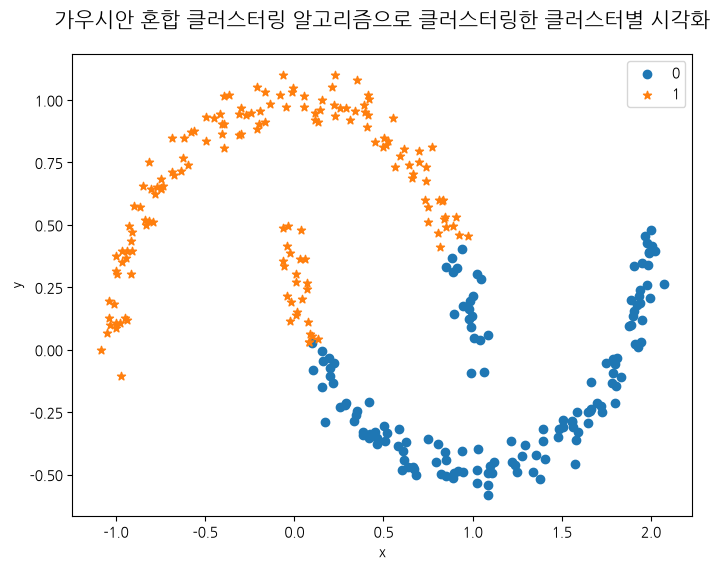

In [14]:
plt.figure(figsize=[8, 6])
markers = ['o', '*']

for index, marker in enumerate(markers):
    df_index = df[df.label_2 == index]
    plt.scatter(x=df_index.x, y=df_index.y, label=index, marker=marker)

plt.title('가우시안 혼합 클러스터링 알고리즘으로 클러스터링한 클러스터별 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [15]:
score = silhouette_score(x_train, model.fit_predict(x_train))
print(score)

0.4642482004629113


## 밀도 기반 클러스터링 모델을 만들고 학습 시킨다.

밀도 기반 클러스터링 알고리즘을 사용하기 위해 DBSCAN을 import 한다.

In [16]:
from sklearn.cluster import DBSCAN

min_samples에 일정 반경내에 필요한 최소한의 데이터의 개수를 지정하고 eps에 데이터 개수를 측정할 반경을 지정해서 밀도 기반 클러스터링 모델을 만들고 군집화할 데이터를 넘겨서 학습시킨다.

In [17]:
model = DBSCAN(min_samples=5, eps=0.2)
model.fit(x_train)

DBSCAN(eps=0.2)

## 클러스터링 결과를 확인한다.

labels_ 속성으로 클러스터링 결과를 확인할 수 있다.

In [18]:
print(model.labels_)

[0 1 0 0 1 1 1 1 1 1 0 1 1 0 0 0 1 0 1 0 1 1 1 0 0 0 0 1 0 1 1 1 0 0 1 0 0
 1 0 0 0 0 1 1 0 0 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 1
 0 0 0 1 1 1 1 1 1 0 0 1 1 0 1 0 1 1 0 1 0 1 1 0 0 0 0 1 1 1 0 1 0 1 0 0 1
 1 1 1 1 0 0 0 0 1 1 0 1 1 1 0 0 1 0 1 1 1 0 0 1 0 1 1 1 1 1 0 1 0 0 0 0 1
 0 1 0 1 0 0 1 0 0 1 0 0 0 0 1 1 0 1 0 1 1 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0
 1 0 0 1 1 1 0 1 1 0 1 0 0 0 1 0 0 1 1 0 0 1 1 0 1 1 0 1 1 1 1 0 0 0 0 0 0
 0 1 1 1 1 1 1 1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 1 0 1 1 0 0 0 1 1 1 0 1 0 1 0
 1 0 1 0 0 1 1 1 1 0 1 1 0 0 1 0 1 0 1 1 0 0 1 1 1 1 0 0 0 0 1 1 1 0 1 1 0
 1 1 0 1]


fit_predict() 메소드에 피처 데이터를 넘겨서 예측하면 클러스터링과 같은 결과가 나온다.

In [19]:
print(model.fit_predict(x_train))

[0 1 0 0 1 1 1 1 1 1 0 1 1 0 0 0 1 0 1 0 1 1 1 0 0 0 0 1 0 1 1 1 0 0 1 0 0
 1 0 0 0 0 1 1 0 0 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 1
 0 0 0 1 1 1 1 1 1 0 0 1 1 0 1 0 1 1 0 1 0 1 1 0 0 0 0 1 1 1 0 1 0 1 0 0 1
 1 1 1 1 0 0 0 0 1 1 0 1 1 1 0 0 1 0 1 1 1 0 0 1 0 1 1 1 1 1 0 1 0 0 0 0 1
 0 1 0 1 0 0 1 0 0 1 0 0 0 0 1 1 0 1 0 1 1 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0
 1 0 0 1 1 1 0 1 1 0 1 0 0 0 1 0 0 1 1 0 0 1 1 0 1 1 0 1 1 1 1 0 0 0 0 0 0
 0 1 1 1 1 1 1 1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 1 0 1 1 0 0 0 1 1 1 0 1 0 1 0
 1 0 1 0 0 1 1 1 1 0 1 1 0 0 1 0 1 0 1 1 0 0 1 1 1 1 0 0 0 0 1 1 1 0 1 1 0
 1 1 0 1]


## 데이터프레임을 만들고 파생 변수를 만들고 각 데이터가 할당된 클러스터를 넣어준다.

In [20]:
df = pd.DataFrame(x_train, columns=['x', 'y'])
df['label_1'] = y_train # make_blobs() 메소드를 실행해서 얻은 클러스터의 중심
df['label_2'] = model.fit_predict(x_train) # 밀도 기반 클러스터링 알고리즘으로 얻은 클러스터의 중심
df.head(20)

,x,y,label_1,label_2
0,0.257874,-0.230961,1,0
1,-0.686251,0.710652,0,1
2,0.847431,-0.411507,1,0
3,0.197781,-0.071909,1,0
4,0.914972,0.325733,0,1
5,-0.952019,0.128681,0,1
6,0.514135,0.820107,0,1
7,0.118170,0.948977,0,1
8,-1.038048,0.125257,0,1
9,-0.914294,0.303833,0,1


## 밀도 기반 클러스터링 적용 후 데이터 시각화

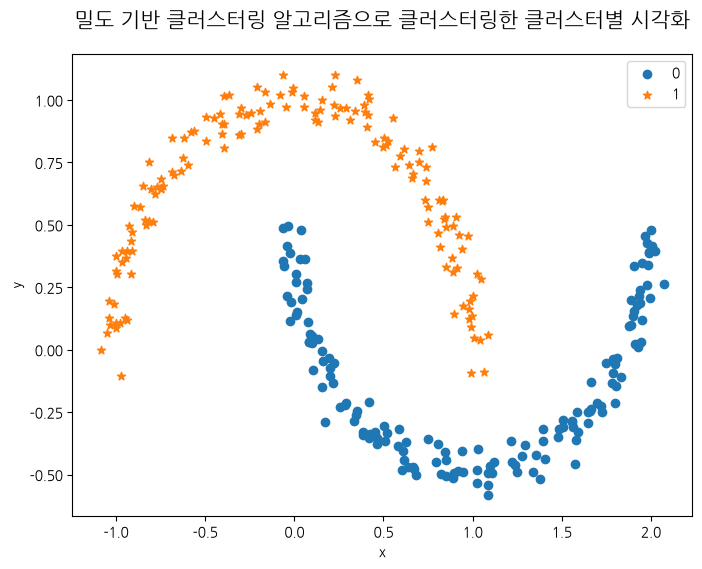

In [21]:
plt.figure(figsize=[8, 6])
markers = ['o', '*']

for index, marker in enumerate(markers):
    df_index = df[df.label_2 == index]
    plt.scatter(x=df_index.x, y=df_index.y, label=index, marker=marker)

plt.title('밀도 기반 클러스터링 알고리즘으로 클러스터링한 클러스터별 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## 모델을 평가한다.

In [22]:
score = silhouette_score(x_train, model.fit_predict(x_train))
print(score)

0.3252753437419221
